# Maternal Satisfaction ML Project
## Maternal Satisfaction Among Vaginal and Cesarean Section Delivery Care Services
### Bahir Dar City Health Facilities, Northwest Ethiopia
#### Application of Machine Learning (Logistic Regression)

**Dataset:** Delivery care satisfaction.sav (SPSS format)  
**Dependent Variable:** `satisfaction` (1 = Not Satisfied, 2 = Satisfied)  
**Algorithm:** Logistic Regression  


---
## Step 1: Import All Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import pyreadstat
import joblib
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss,
    confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
print('All libraries imported successfully.')


All libraries imported successfully.


---
## Step 2: Load the SPSS Dataset

In [2]:
# Load the SPSS (.sav) file using pyreadstat
data, meta = pyreadstat.read_sav('Delivery care satisfaction.sav')

print(f'Dataset loaded successfully.')
print(f'Shape: {data.shape[0]} observations x {data.shape[1]} variables')


Dataset loaded successfully.
Shape: 894 observations x 46 variables


---
## Step 3: Data Understanding
### 3.1 Variable Overview

In [3]:
# Display all column names
print('All variables in the dataset:')
for i, col in enumerate(data.columns, start=1):
    label = meta.column_names_to_labels.get(col, 'No label')
    print(f'  {i:2d}. {col:<40} {label}')


All variables in the dataset:
   1. q101age                                  None
   2. q102mstatu                               marital status
   3. q103religi                               religion
   4. q104ethini                               ethinicity
   5. q105educat                               educational status
   6. q106occupa                               occupation
   7. q107mincom                               monthly income
   8. q108reside                               residence
   9. q1091distk                               distance in kelometers
  10. q1092disth                               None
  11. q110reason                               reasons to visit hospital
  12. q111timeta                               time taken to get professionals
  13. q112waitpl                               presence of waiting area
  14. q113privac                               gender privacy during physical examination
  15. q201parity                               no of children
 

### 3.2 First and Last 5 Rows

In [4]:
data.head()

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,q110reason,q111timeta,q112waitpl,q113privac,q201parity,q202cpplan,q203ancatt,q204hivres,q205ga,q206delimo,q207nstatu,q208pdhsta,q209nsex,q2010bw,q301greeti,q302respec,q303delive,q411owners,ageafterrecod,monthlyincomerecode,gestationaagerecode,birthweightofbaby,satisfaction,modeofdeliveryrecode,waitingtimerecode,privacyrecode,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
0,22.00,2.00,1.00,1.00,4.00,88.00,800.00,2.00,0.00,200.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,41.00,1.00,1.00,1.00,1.00,1111.00,1.00,1.00,1.00,2.00,2.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00
1,35.00,2.00,1.00,3.00,4.00,2.00,7000.00,1.00,0.00,50.00,1.00,1.00,1.00,1.00,3.00,1.00,1.00,2.00,41.00,1.00,1.00,1.00,1.00,3000.00,1.00,1.00,1.00,2.00,3.00,4.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00
2,20.00,2.00,1.00,1.00,5.00,2.00,1500.00,1.00,5.00,NaN,1.00,1.00,1.00,1.00,2.00,1.00,1.00,2.00,42.00,1.00,1.00,1.00,1.00,3000.00,1.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,NaN
3,26.00,2.00,1.00,1.00,3.00,3.00,900.00,1.00,0.00,11.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,2.00,39.00,1.00,1.00,1.00,2.00,2600.00,1.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00
4,22.00,2.00,2.00,1.00,6.00,5.00,1536.00,2.00,5.00,NaN,2.00,1.00,2.00,1.00,2.00,1.00,1.00,2.00,39.00,2.00,2.00,2.00,1.00,2800.00,1.00,1.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,NaN


In [5]:
data.tail()

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,q110reason,q111timeta,q112waitpl,q113privac,q201parity,q202cpplan,q203ancatt,q204hivres,q205ga,q206delimo,q207nstatu,q208pdhsta,q209nsex,q2010bw,q301greeti,q302respec,q303delive,q411owners,ageafterrecod,monthlyincomerecode,gestationaagerecode,birthweightofbaby,satisfaction,modeofdeliveryrecode,waitingtimerecode,privacyrecode,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
889,29.00,3.00,2.00,2.00,6.00,88.00,2200.00,1.00,30.00,NaN,2.00,2.00,2.00,2.00,2.00,1.00,1.00,3.00,41.00,2.00,1.00,1.00,1.00,3600.00,1.00,1.00,2.00,2.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
890,31.00,2.00,1.00,1.00,7.00,1.00,4530.00,1.00,20.00,NaN,2.00,1.00,2.00,2.00,2.00,2.00,2.00,3.00,37.00,2.00,1.00,1.00,1.00,2900.00,2.00,2.00,2.00,2.00,3.00,3.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
891,21.00,2.00,1.00,1.00,6.00,3.00,2500.00,1.00,0.00,1.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,3.00,43.00,2.00,1.00,2.00,2.00,3000.00,2.00,2.00,2.00,2.00,2.00,2.00,3.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,NaN
892,18.00,1.00,2.00,1.00,7.00,1.00,3230.00,1.00,15.00,NaN,1.00,2.00,2.00,2.00,1.00,1.00,1.00,2.00,43.00,1.00,1.00,1.00,1.00,2001.00,1.00,2.00,2.00,2.00,1.00,3.00,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,NaN
893,22.00,3.00,2.00,4.00,6.00,2.00,1500.00,1.00,10.00,1.00,2.00,2.00,2.00,2.00,1.00,1.00,1.00,2.00,37.00,1.00,1.00,1.00,2.00,3100.00,1.00,1.00,2.00,2.00,2.00,1.00,1.00,2.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,NaN


### 3.3 Data Types and Non-Null Counts

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 894 entries, 0 to 893
Data columns (total 46 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   q101age                                894 non-null    float64
 1   q102mstatu                             894 non-null    float64
 2   q103religi                             894 non-null    float64
 3   q104ethini                             894 non-null    float64
 4   q105educat                             894 non-null    float64
 5   q106occupa                             894 non-null    float64
 6   q107mincom                             894 non-null    float64
 7   q108reside                             894 non-null    float64
 8   q1091distk                             894 non-null    float64
 9   q1092disth                             320 non-null    float64
 10  q110reason                             894 non-null    float64
 11  q111timeta       

### 3.4 Missing Values

In [7]:
missing = data.isnull().sum()
missing_pct = (missing / len(data) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing (%)': missing_pct
})
print('Variables with missing values:')
print(missing_df[missing_df['Missing Count'] > 0].to_string())
print(f'\nTotal missing values: {missing.sum()}')
print(f'Total complete rows: {data.dropna().shape[0]}')


Variables with missing values:
                            Missing Count  Missing (%)
q1092disth                            574        64.21
wolkingdistancerecodeinhrs            619        69.24

Total missing values: 1193
Total complete rows: 275


### 3.5 Duplicate Rows

In [8]:
print('Number of duplicate rows:', data.duplicated().sum())

Number of duplicate rows: 0


### 3.6 Value Labels from SPSS Metadata

In [9]:
# Show SPSS value labels for all categorical variables
for col in data.columns:
    labels = meta.variable_value_labels.get(col)
    if labels:
        print(f'\n{col}')
        print('-' * 40)
        for code, label in labels.items():
            print(f'  {code} = {label}')



q102mstatu
----------------------------------------
  1.0 = single
  2.0 = married
  3.0 = cohabited
  4.0 = widowed
  5.0 = divorced

q103religi
----------------------------------------
  1.0 = orthodox
  2.0 = muslim
  3.0 = protestant
  4.0 = orhers

q104ethini
----------------------------------------
  1.0 = amhara
  2.0 = oromo
  3.0 = tigrie
  4.0 = agew
  88.0 = others

q105educat
----------------------------------------
  1.0 = able to read and write
  2.0 = unable to read and write
  3.0 = grade 1 to 4
  4.0 = grade 5 to 8
  5.0 = grade 9 to 10
  6.0 = grade 11 to 12
  7.0 = diploma and above

q106occupa
----------------------------------------
  1.0 = governmental
  2.0 = merchants
  3.0 = huose wife
  4.0 = farmer
  5.0 = students
  88.0 = others

q108reside
----------------------------------------
  1.0 = urban
  2.0 = rural

q110reason
----------------------------------------
  1.0 = planed
  2.0 = refered

q111timeta
----------------------------------------
  1.0 = <1hr


### 3.7 Variable Summary Table

In [10]:
variable_summary = pd.DataFrame({
    'Variable': data.columns,
    'Label': [meta.column_names_to_labels.get(c, '') for c in data.columns],
    'Data_Type': data.dtypes.astype(str).values,
    'Missing': data.isnull().sum().values,
    'Missing_%': (data.isnull().sum() / len(data) * 100).round(2).values,
    'Unique_Values': data.nunique().values
})
print(variable_summary.to_string(index=False))


                             Variable                                                                  Label Data_Type  Missing  Missing_%  Unique_Values
                              q101age                                                                    NaN   float64        0       0.00             24
                           q102mstatu                                                         marital status   float64        0       0.00              5
                           q103religi                                                               religion   float64        0       0.00              4
                           q104ethini                                                             ethinicity   float64        0       0.00              4
                           q105educat                                                     educational status   float64        0       0.00              7
                           q106occupa                                       

### 3.8 Target Variable Distribution

Satisfaction variable distribution:
  1.0 (not satisfied): 345 (38.6%)
  2.0 (satisfied): 549 (61.4%)


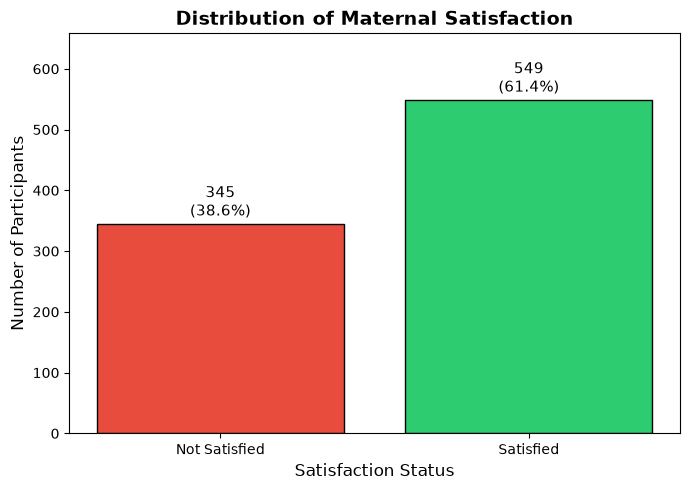

Class imbalance ratio (Not Satisfied : Satisfied) = 345 : 549


In [11]:
target_counts = data['satisfaction'].value_counts().sort_index()
target_pct = (data['satisfaction'].value_counts(normalize=True).sort_index() * 100).round(1)

print('Satisfaction variable distribution:')
for code, cnt in target_counts.items():
    label = meta.variable_value_labels['satisfaction'].get(code, str(code))
    print(f'  {code} ({label}): {cnt} ({target_pct[code]:.1f}%)')

# Bar chart
labels = ['Not Satisfied', 'Satisfied']
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, target_counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black')
for bar, cnt, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f'{cnt}\n({pct}%)', ha='center', va='bottom', fontsize=11)
ax.set_title('Distribution of Maternal Satisfaction', fontsize=14, fontweight='bold')
ax.set_xlabel('Satisfaction Status', fontsize=12)
ax.set_ylabel('Number of Participants', fontsize=12)
ax.set_ylim(0, max(target_counts.values) * 1.2)
plt.tight_layout()
plt.show()
print(f'Class imbalance ratio (Not Satisfied : Satisfied) = {target_counts[1.0]} : {target_counts[2.0]}')


---
## Step 4: Descriptive Statistics
### 4.1 Numerical Variables Summary

In [12]:
numerical_variables = [
    'q101age',    # Age of the mother
    'q107mincom', # Monthly income
    'q1091distk', # Distance in kilometers
    'q1092disth', # Distance in hours (has missing values)
    'q205ga',     # Gestational age (weeks)
    'q2010bw'     # Birth weight (grams)
]

num_summary = data[numerical_variables].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).T
num_summary.insert(2, 'variance', data[numerical_variables].var())
num_summary.columns = [
    'Count', 'Mean', 'Variance', 'Std', 'Min',
    'P10', 'P25', 'P50 (Median)', 'P75', 'P90', 'Max'
]
print('Descriptive Statistics - Numerical Variables')
print('=' * 80)
print(num_summary.round(2).to_string())


Descriptive Statistics - Numerical Variables
            Count    Mean    Variance     Std     Min     P10     P25  P50 (Median)     P75     P90      Max
q101age    894.00   26.60       23.83    4.88   17.00   20.00   23.00         27.00   30.00   33.00    42.00
q107mincom 894.00 4096.88 19983706.40 4470.31  200.00  853.00 1537.75       3000.00 5300.00 7650.00 50000.00
q1091distk 894.00   19.29     1956.16   44.23    0.00    0.00    0.00          5.00   15.00   50.00   500.00
q1092disth 320.00   16.67      282.75   16.82    1.00    2.00    4.00         12.00   30.00   30.00   200.00
q205ga     894.00   39.40        2.41    1.55   32.00   37.00   39.00         39.00   40.00   42.00    43.00
q2010bw    894.00 2941.73   292048.23  540.41 1111.00 2200.00 2600.00       2900.00 3200.00 3600.00  5001.00


### 4.2 Frequency Tables for Categorical Variables

In [13]:
categorical_variables = [
    'q102mstatu', 'q103religi', 'q104ethini', 'q105educat',
    'q106occupa', 'q108reside', 'q110reason', 'q111timeta',
    'q112waitpl', 'q113privac', 'q201parity', 'q202cpplan',
    'q203ancatt', 'q204hivres', 'q206delimo', 'q207nstatu',
    'q208pdhsta', 'q209nsex', 'q301greeti', 'q302respec',
    'q303delive', 'q411owners', 'ageafterrecod',
    'monthlyincomerecode', 'gestationaagerecode',
    'birthweightofbaby', 'modeofdeliveryrecode',
    'waitingtimerecode', 'privacyrecode',
    'encourageandsupportatdeliveryrecode', 'politenessrecode',
    'availabilityofmedicalequipmentsrecode', 'counselingrecode',
    'overallcleanessrecode', 'accessandcleanessoftoiletrecode',
    'waitingareacleanessandconfort', 'availabilityofbedintheward',
    'distancerecode1', 'wolkingdistancerecodeinhrs'
]

def labeled_frequency_table(df, variable, spss_meta):
    freq = df[variable].value_counts(dropna=False).sort_index()
    pct = (df[variable].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2)
    labels_map = spss_meta.variable_value_labels.get(variable, {})
    label_col = [labels_map.get(k, str(k)) for k in freq.index]
    table = pd.DataFrame({
        'Code': freq.index,
        'Label': label_col,
        'Frequency': freq.values,
        'Percentage (%)': pct.values
    })
    return table

for var in categorical_variables:
    label = meta.column_names_to_labels.get(var, var)
    print(f'\n{"-" * 60}')
    print(f'{var}: {label}')
    print(f'{"-" * 60}')
    print(labeled_frequency_table(data, var, meta).to_string(index=False))



------------------------------------------------------------
q102mstatu: marital status
------------------------------------------------------------
 Code     Label  Frequency  Percentage (%)
 1.00    single         98           10.96
 2.00   married        712           79.64
 3.00 cohabited         67            7.49
 4.00   widowed         10            1.12
 5.00  divorced          7            0.78

------------------------------------------------------------
q103religi: religion
------------------------------------------------------------
 Code      Label  Frequency  Percentage (%)
 1.00   orthodox        608           68.01
 2.00     muslim        193           21.59
 3.00 protestant         88            9.84
88.00       88.0          5            0.56

------------------------------------------------------------
q104ethini: ethinicity
------------------------------------------------------------
 Code  Label  Frequency  Percentage (%)
 1.00 amhara        715           79.98
 2

### 4.3 Key Visualizations

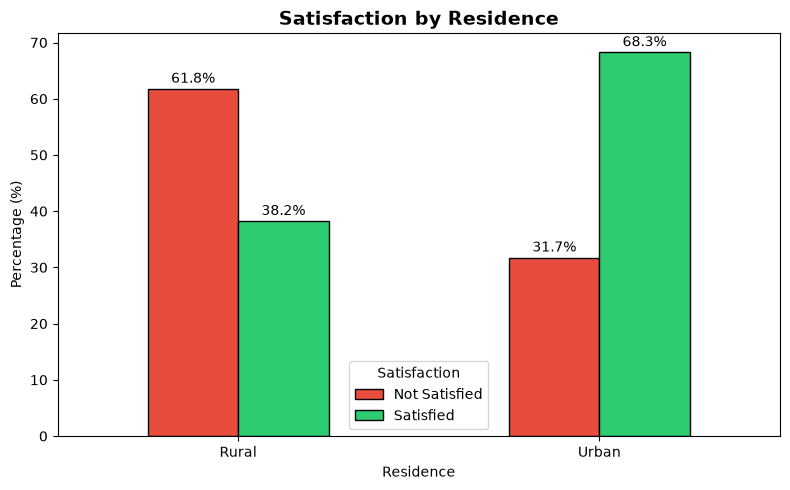

In [14]:
# Satisfaction by Residence
data['residence_label'] = data['q108reside'].map({1.0: 'Urban', 2.0: 'Rural'})
res_table = pd.crosstab(data['residence_label'], data['satisfaction'], normalize='index') * 100
res_table.columns = ['Not Satisfied', 'Satisfied']
ax = res_table.plot(kind='bar', figsize=(8, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=0)
ax.set_title('Satisfaction by Residence', fontsize=14, fontweight='bold')
ax.set_xlabel('Residence')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=2)
plt.tight_layout()
plt.show()


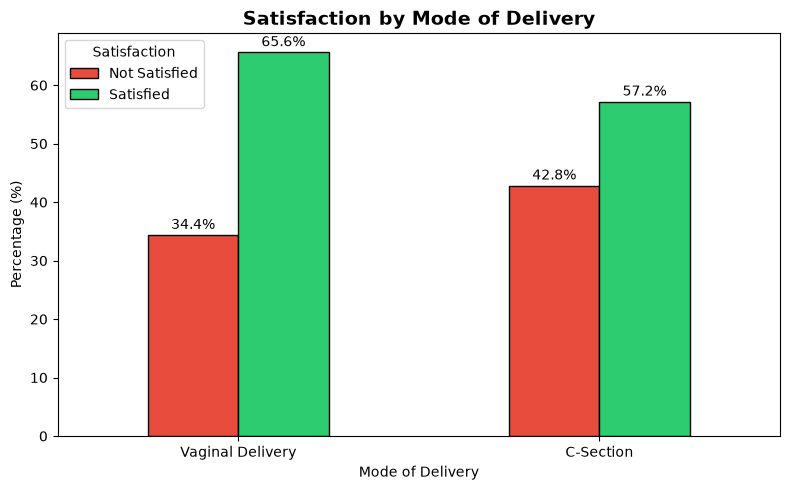

In [15]:
# Satisfaction by Mode of Delivery
del_table = pd.crosstab(data['modeofdeliveryrecode'],
                        data['satisfaction'], normalize='index') * 100
del_table.columns = ['Not Satisfied', 'Satisfied']
del_table.index = ['Vaginal Delivery', 'C-Section']
ax = del_table.plot(kind='bar', figsize=(8, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=0)
ax.set_title('Satisfaction by Mode of Delivery', fontsize=14, fontweight='bold')
ax.set_xlabel('Mode of Delivery')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge', padding=2)
plt.tight_layout()
plt.show()


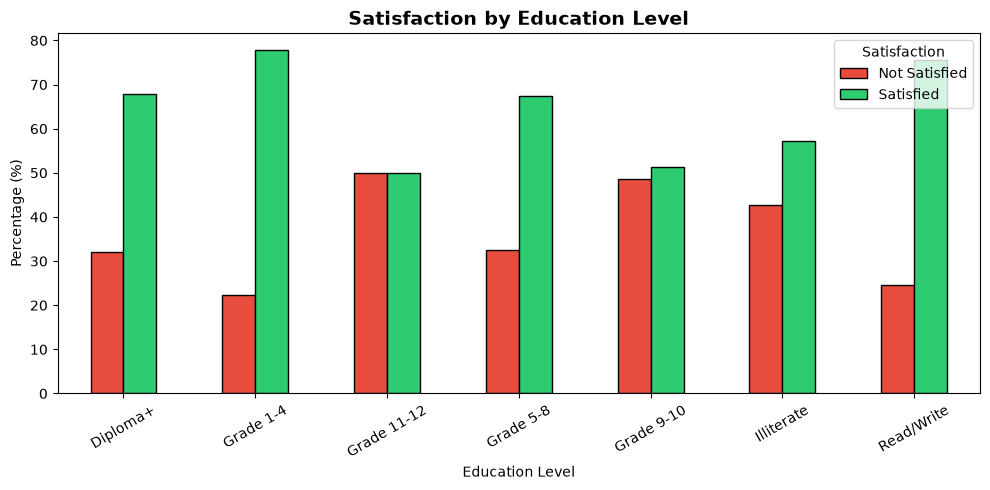

In [16]:
# Satisfaction by Education Level
edu_map = {
    1.0: 'Read/Write', 2.0: 'Illiterate', 3.0: 'Grade 1-4',
    4.0: 'Grade 5-8', 5.0: 'Grade 9-10', 6.0: 'Grade 11-12', 7.0: 'Diploma+'
}
data['edu_label'] = data['q105educat'].map(edu_map)
edu_table = pd.crosstab(data['edu_label'], data['satisfaction'], normalize='index') * 100
edu_table.columns = ['Not Satisfied', 'Satisfied']
ax = edu_table.plot(kind='bar', figsize=(10, 5), color=['#e74c3c', '#2ecc71'],
                    edgecolor='black', rot=30)
ax.set_title('Satisfaction by Education Level', fontsize=14, fontweight='bold')
ax.set_xlabel('Education Level')
ax.set_ylabel('Percentage (%)')
ax.legend(title='Satisfaction')
plt.tight_layout()
plt.show()


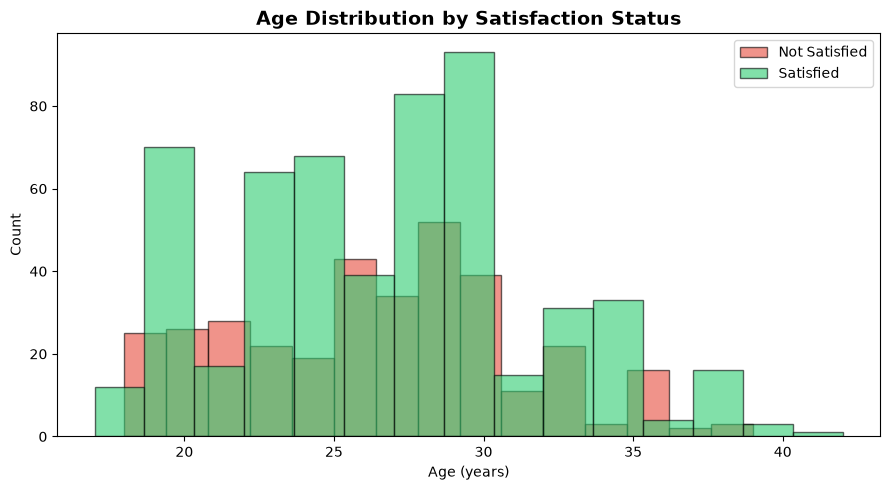

In [17]:
# Age distribution by Satisfaction
fig, ax = plt.subplots(figsize=(9, 5))
for sat_val, color, label in [(1.0, '#e74c3c', 'Not Satisfied'), (2.0, '#2ecc71', 'Satisfied')]:
    subset = data[data['satisfaction'] == sat_val]['q101age'].dropna()
    ax.hist(subset, bins=15, alpha=0.6, color=color, label=label, edgecolor='black')
ax.set_title('Age Distribution by Satisfaction Status', fontsize=14, fontweight='bold')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()


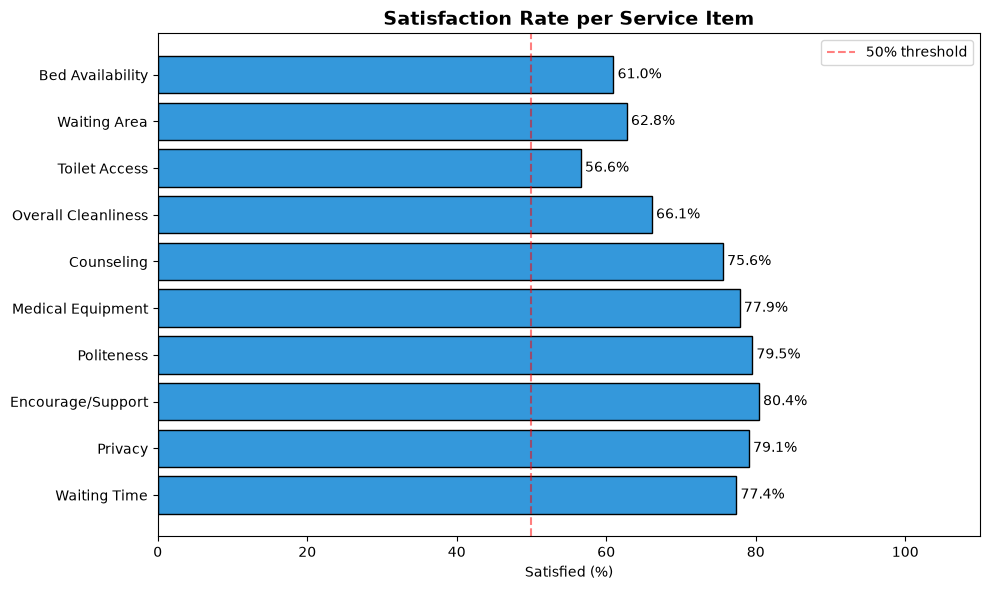

In [18]:
# Satisfaction-related service items
service_vars = [
    'waitingtimerecode', 'privacyrecode',
    'encourageandsupportatdeliveryrecode', 'politenessrecode',
    'availabilityofmedicalequipmentsrecode', 'counselingrecode',
    'overallcleanessrecode', 'accessandcleanessoftoiletrecode',
    'waitingareacleanessandconfort', 'availabilityofbedintheward'
]
service_labels = [
    'Waiting Time', 'Privacy', 'Encourage/Support',
    'Politeness', 'Medical Equipment', 'Counseling',
    'Overall Cleanliness', 'Toilet Access', 'Waiting Area', 'Bed Availability'
]

# Percentage satisfied per service item
sat_rates = [(data[v] == 2.0).mean() * 100 for v in service_vars]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(service_labels, sat_rates, color='#3498db', edgecolor='black')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlim(0, 110)
ax.set_title('Satisfaction Rate per Service Item', fontsize=14, fontweight='bold')
ax.set_xlabel('Satisfied (%)')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')
ax.legend()
plt.tight_layout()
plt.show()


---
## Step 5: Data Preparation & Feature Engineering

### 5.1 Encode Target Variable

In [19]:
# Recode: 1.0 (Not Satisfied) -> 0, 2.0 (Satisfied) -> 1
data['satisfaction_binary'] = data['satisfaction'].map({1.0: 0, 2.0: 1})
print('Target variable encoding:')
print('  1.0 (Not Satisfied) -> 0')
print('  2.0 (Satisfied)     -> 1')
print()
print(data['satisfaction_binary'].value_counts())


Target variable encoding:
  1.0 (Not Satisfied) -> 0
  2.0 (Satisfied)     -> 1

satisfaction_binary
1    549
0    345
Name: count, dtype: int64


### 5.2 Define Candidate Feature Set
> Drop raw/continuous variables that have been recoded (use only the recoded versions),satisfaction related and exclude the target and its original form.

In [20]:
# Candidate features: exclude raw variables already recoded and target columns
candidate_features = [
    # Socio-demographic
    'ageafterrecod',          # Age group
    'q102mstatu',             # Marital status
    'q103religi',             # Religion
    'q104ethini',             # Ethnicity
    'q105educat',             # Education
    'q106occupa',             # Occupation
    'monthlyincomerecode',    # Monthly income group
    'q108reside',             # Residence
    # Access
    'distancerecode1',        # Distance (<= / > 10 km)
    'q110reason',             # Reason for visit (planned/referred)
    'q111timeta',             # Time to reach facility
    'q112waitpl',             # Waiting place available
    'q113privac',             # Privacy during examination
    # Obstetric
    'q201parity',             # Parity
    'q202cpplan',             # Current pregnancy planned
    'q203ancatt',             # ANC attendance
    'q204hivres',             # HIV status
    'gestationaagerecode',    # Gestational age group
    'modeofdeliveryrecode',   # Mode of delivery
    'q207nstatu',             # Neonatal outcome
    'q208pdhsta',             # Post-delivery health problem
    'q209nsex',               # Sex of baby
    'birthweightofbaby',      # Birth weight group
    # Care quality
    'q301greeti',             # Greeting by professional
    'q302respec',             # Respectful practice
    'q303delive',             # Sex of health provider
    'q411owners',             # Facility ownership

]

print(f'Number of candidate features: {len(candidate_features)}')
print('Missing values in candidate features:')
missing_cand = data[candidate_features].isnull().sum()
print(missing_cand[missing_cand > 0])
print('\nNo missing values found.' if missing_cand.sum() == 0 else '')


Number of candidate features: 27
Missing values in candidate features:
Series([], dtype: int64)

No missing values found.


### 5.3 Define Feature Types

In [21]:
# All features are categorical (coded as float from SPSS)
# Only distancerecode1 is already binary (1/2), we treat all as categorical
numerical_features = []   # No raw continuous predictors used (all recoded)
categorical_features = candidate_features.copy()

print(f'Categorical features: {len(categorical_features)}')
print(f'Numerical features:   {len(numerical_features)}')


Categorical features: 27
Numerical features:   0


### 5.4 Prepare X and y

In [22]:
X = data[candidate_features].copy()
y = data['satisfaction_binary'].copy()

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Class distribution:')
print(y.value_counts())


X shape: (894, 27)
y shape: (894,)
Class distribution:
satisfaction_binary
1    549
0    345
Name: count, dtype: int64


### 5.5 Train / Test Split (80% / 20%, stratified)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print(f'Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Test set:     {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)')
print()
print('Train class distribution:')
print(y_train.value_counts())
print('Test class distribution:')
print(y_test.value_counts())


Training set: 715 samples (80.0%)
Test set:     179 samples (20.0%)

Train class distribution:
satisfaction_binary
1    439
0    276
Name: count, dtype: int64
Test class distribution:
satisfaction_binary
1    110
0     69
Name: count, dtype: int64


---
## Step 6: Build Preprocessing Pipeline

In [24]:
# Preprocessor: OneHotEncode all categorical features
# (no numerical features; all predictors are coded ordinal/nominal from SPSS)
preprocessor_full = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first',
                              sparse_output=False), categorical_features)
    ],
    remainder='drop'
)

# Fit on training set, transform both
X_train_proc = preprocessor_full.fit_transform(X_train)
X_test_proc  = preprocessor_full.transform(X_test)

print('Processed training shape:', X_train_proc.shape)
print('Processed test shape:    ', X_test_proc.shape)


Processed training shape: (715, 50)
Processed test shape:     (179, 50)


---
## Step 7: Feature Selection
> Reduce from all candidate features to the most important predictors using 5-fold cross-validated permutation importance.

In [25]:
# Step 7A: Fit a baseline Logistic Regression for permutation importance
base_pipeline = Pipeline([
    ('preprocessor', preprocessor_full),
    ('classifier', LogisticRegression(
        max_iter=1000,class_weight='balanced', random_state=42, solver='lbfgs', C=1.0
    ))
])

base_pipeline.fit(X_train, y_train)
print('Baseline model trained on all candidate features.')
print('Baseline accuracy:', accuracy_score(y_test, base_pipeline.predict(X_test)))


Baseline model trained on all candidate features.
Baseline accuracy: 0.7988826815642458


In [26]:
# Step 7B: Permutation importance on test set (5 repeats)
perm_imp = permutation_importance(
    base_pipeline, X_test, y_test,
    scoring='roc_auc',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': candidate_features,
    'Importance_Mean': perm_imp.importances_mean,
    'Importance_Std': perm_imp.importances_std
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

print('Permutation Importance (top 20):')
print(importance_df.head(20).to_string(index=False))


Permutation Importance (top 20):
            Feature  Importance_Mean  Importance_Std
         q411owners             0.02            0.01
         q301greeti             0.02            0.01
         q112waitpl             0.02            0.01
         q113privac             0.02            0.01
    distancerecode1             0.01            0.01
         q302respec             0.01            0.01
         q110reason             0.01            0.00
         q111timeta             0.01            0.01
         q108reside             0.01            0.00
         q102mstatu             0.00            0.00
         q208pdhsta             0.00            0.00
monthlyincomerecode             0.00            0.00
      ageafterrecod             0.00            0.00
         q303delive             0.00            0.00
         q204hivres             0.00            0.00
  birthweightofbaby             0.00            0.00
         q103religi             0.00            0.00
         q104

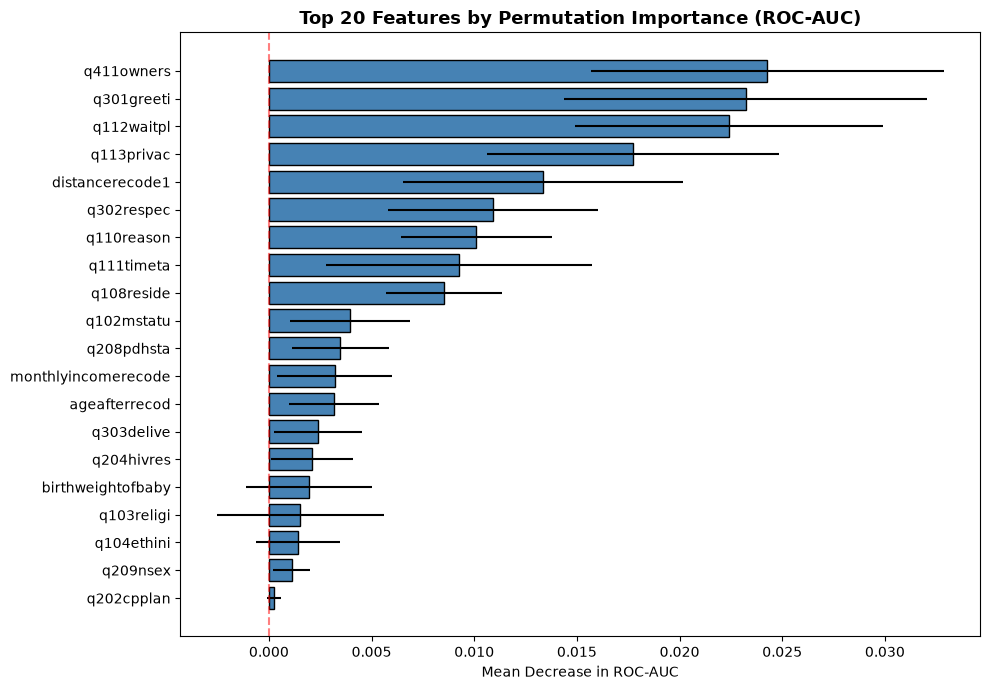

In [27]:
# Step 7C: Visualize permutation importance
top_n = importance_df.head(20)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_n['Feature'][::-1], top_n['Importance_Mean'][::-1],
        xerr=top_n['Importance_Std'][::-1], color='steelblue', edgecolor='black')
ax.set_title('Top 20 Features by Permutation Importance (ROC-AUC)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in ROC-AUC')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [28]:
# Step 7D: Select top 10 features
top10_features = importance_df.head(10)['Feature'].tolist()
print('Selected top 10 features:')
for i, f in enumerate(top10_features, 1):
    label = meta.column_names_to_labels.get(f, f)
    print(f'  {i:2d}. {f:<45} {label}')


Selected top 10 features:
   1. q411owners                                    ownership of the facility/hospital
   2. q301greeti                                    was the professional give greeting for you?
   3. q112waitpl                                    presence of waiting area
   4. q113privac                                    gender privacy during physical examination
   5. distancerecode1                               distance after recode1
   6. q302respec                                    respectfull practice of the professional during delivery process
   7. q110reason                                    reasons to visit hospital
   8. q111timeta                                    time taken to get professionals
   9. q108reside                                    residence
  10. q102mstatu                                    marital status


---
## Step 8: Build & Train Final Logistic Regression Model (Top 10 Features)

In [29]:
# Create reduced datasets
X_train_red = X_train[top10_features].copy()
X_test_red  = X_test[top10_features].copy()

print('Reduced training shape:', X_train_red.shape)
print('Reduced test shape:    ', X_test_red.shape)


Reduced training shape: (715, 10)
Reduced test shape:     (179, 10)


In [30]:
# Identify feature types within the reduced set
numerical_red = []  # no continuous variables in reduced set
categorical_red = top10_features.copy()

# Preprocessor for reduced feature set
preprocessor_red = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first',
                              sparse_output=False), categorical_red)
    ],
    remainder='drop'
)

# Final pipeline
final_model = Pipeline([
    ('preprocessor', preprocessor_red),
    ('classifier', LogisticRegression(
        max_iter=1000,class_weight='balanced', random_state=42, solver='lbfgs', C=1.0
    ))
])

final_model.fit(X_train_red, y_train)
print('Final Logistic Regression model trained successfully.')


Final Logistic Regression model trained successfully.


In [31]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
param_grid = {"classifier__C": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(final_model, param_grid, scoring="precision", cv=cv, n_jobs=-1)
grid.fit(X_train_red, y_train)
print("Best C:", grid.best_params_)
logistic_model_reduced = grid.best_estimator_  # replace with the tuned version
#y_pred_red = logistic_model_reduced.predict(X_test_red)
y_prob_red = logistic_model_reduced.predict_proba(X_test_red)[:, 1]

Best C: {'classifier__C': 0.3}


In [52]:
threshold = 0.45 # try 0.55–0.75 depending on how much recall you can sacrifice
y_pred_custom = (y_prob_red >= threshold).astype(int)
from sklearn.metrics import precision_score, recall_score
print("Precision:", precision_score(y_test, y_pred_custom))
print("Recall:", recall_score(y_test, y_pred_custom))

Precision: 0.8387096774193549
Recall: 0.9454545454545454


---
## Step 9: Hyperparameter Tuning (GridSearchCV)

In [47]:
param_grid = {'classifier__C': [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]}
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    final_model,
    param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_red, y_train)

print('Best hyperparameter:', grid_search.best_params_)
print('Best CV ROC-AUC:    ', round(grid_search.best_score_, 4))

# Use the best model going forward
best_model = grid_search.best_estimator_


Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best hyperparameter: {'classifier__C': 0.1}
Best CV ROC-AUC:     0.9066


---
## Step 10: Model Evaluation
### 10.1 Test Set Performance

In [54]:
y_pred  = best_model.predict(X_test_red)
y_prob  = best_model.predict_proba(X_test_red)[:, 1]

accuracy  = accuracy_score(y_test, y_pred_custom)
precision = precision_score(y_test, y_pred_custom)
recall    = recall_score(y_test, y_pred_custom)
f1        = f1_score(y_test, y_pred_custom)
roc_auc   = roc_auc_score(y_test, y_prob)
brier     = brier_score_loss(y_test, y_prob)

print('Model Performance Metrics')
print('=' * 45)
print(f'  Accuracy      : {accuracy:.4f}  ({accuracy*100:.2f}%)')
print(f'  Precision     : {precision:.4f}  ({precision*100:.2f}%)')
print(f'  Recall        : {recall:.4f}  ({recall*100:.2f}%)')
print(f'  F1 Score      : {f1:.4f}  ({f1*100:.2f}%)')
print(f'  ROC-AUC       : {roc_auc:.4f}  ({roc_auc*100:.2f}%)')
print(f'  Brier Score   : {brier:.4f}  (lower is better)')
print('=' * 45)
print()
print('Classification Report:')
print(classification_report(y_test, y_pred_custom,
      target_names=['Not Satisfied', 'Satisfied']))


Model Performance Metrics
  Accuracy      : 0.8547  (85.47%)
  Precision     : 0.8387  (83.87%)
  Recall        : 0.9455  (94.55%)
  F1 Score      : 0.8889  (88.89%)
  ROC-AUC       : 0.9190  (91.90%)
  Brier Score   : 0.1209  (lower is better)

Classification Report:
               precision    recall  f1-score   support

Not Satisfied       0.89      0.71      0.79        69
    Satisfied       0.84      0.95      0.89       110

     accuracy                           0.85       179
    macro avg       0.86      0.83      0.84       179
 weighted avg       0.86      0.85      0.85       179



### 10.2 Confusion Matrix

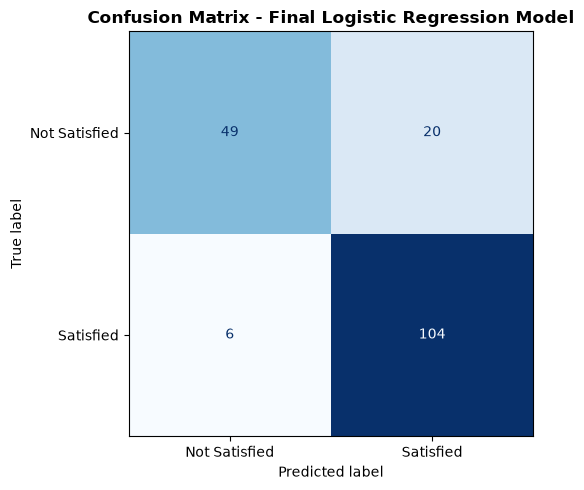

True Negatives  (TN): 49
False Positives (FP): 20
False Negatives (FN): 6
True Positives  (TP): 104
Specificity          : 0.7101


In [55]:
cm = confusion_matrix(y_test, y_pred_custom)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Not Satisfied', 'Satisfied'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix - Final Logistic Regression Model',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Negatives  (TN): {tn}')
print(f'False Positives (FP): {fp}')
print(f'False Negatives (FN): {fn}')
print(f'True Positives  (TP): {tp}')
print(f'Specificity          : {tn/(tn+fp):.4f}')


### 10.3 ROC Curve

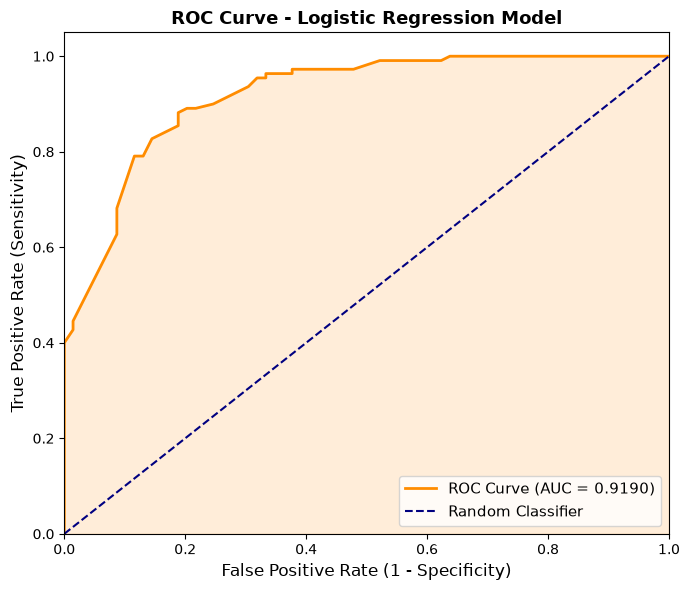

In [36]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2,
        label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Classifier')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curve - Logistic Regression Model', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')
plt.tight_layout()
plt.show()


### 10.4 Cross-Validation Performance

In [37]:
cv_results = cross_validate(
    best_model, X_train_red, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['accuracy', 'roc_auc', 'f1', 'precision', 'recall'],
    return_train_score=False
)

print('5-Fold Cross-Validation Results (Training Set):')
print('=' * 50)
for metric in ['accuracy', 'roc_auc', 'f1', 'precision', 'recall']:
    scores = cv_results[f'test_{metric}']
    print(f'  {metric:<12}: {scores.mean():.4f} (+/- {scores.std():.4f})')


5-Fold Cross-Validation Results (Training Set):
  accuracy    : 0.8322 (+/- 0.0246)
  roc_auc     : 0.9066 (+/- 0.0310)
  f1          : 0.8657 (+/- 0.0179)
  precision   : 0.8541 (+/- 0.0371)
  recall      : 0.8792 (+/- 0.0247)


### 10.5 Threshold Analysis

In [38]:
thresholds_list = np.arange(0.20, 0.81, 0.05)
threshold_results = []

for thresh in thresholds_list:
    y_pred_t = (y_prob >= thresh).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, y_pred_t, labels=[0, 1]).ravel()
    recall_neg = tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0
    recall_pos = tp_t / (tp_t + fn_t) if (tp_t + fn_t) else 0
    threshold_results.append({
        'Threshold': round(thresh, 2),
        'Not Sat. Recall': round(recall_neg, 4),
        'Satisfied Recall': round(recall_pos, 4),
        'Accuracy': round(accuracy_score(y_test, y_pred_t), 4),
        'Precision': round(precision_score(y_test, y_pred_t, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred_t, zero_division=0), 4),
        'TN': tn_t, 'FP': fp_t, 'FN': fn_t, 'TP': tp_t
    })

thresh_df = pd.DataFrame(threshold_results)
print('Threshold Analysis')
print('=' * 90)
print(thresh_df.to_string(index=False))


Threshold Analysis
 Threshold  Not Sat. Recall  Satisfied Recall  Accuracy  Precision  F1-Score  TN  FP  FN  TP
      0.20             0.42              0.99      0.77       0.73      0.84  29  40   1 109
      0.25             0.45              0.99      0.78       0.74      0.85  31  38   1 109
      0.30             0.46              0.99      0.79       0.75      0.85  32  37   1 109
      0.35             0.52              0.97      0.80       0.76      0.86  36  33   3 107
      0.40             0.62              0.97      0.84       0.80      0.88  43  26   3 107
      0.45             0.64              0.96      0.84       0.81      0.88  44  25   4 106
      0.50             0.78              0.89      0.85       0.87      0.88  54  15  12  98
      0.55             0.81              0.88      0.85       0.88      0.88  56  13  13  97
      0.60             0.87              0.79      0.82       0.91      0.84  60   9  23  87
      0.65             0.91              0.68      

---
## Step 11: Feature Importance / Permutation Importance

In [39]:
# Permutation importance on the final reduced model
perm_imp_final = permutation_importance(
    best_model, X_test_red, y_test,
    scoring='roc_auc',
    n_repeats=30,
    random_state=42
)

importance_final = pd.DataFrame({
    'Feature': top10_features,
    'Label': [meta.column_names_to_labels.get(f, f) for f in top10_features],
    'Importance_Mean': perm_imp_final.importances_mean,
    'Importance_Std': perm_imp_final.importances_std
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

print('Permutation Importance - Final Model (Top 10 Features):')
print(importance_final.to_string(index=False))


Permutation Importance - Final Model (Top 10 Features):
        Feature                                                            Label  Importance_Mean  Importance_Std
     q112waitpl                                         presence of waiting area             0.06            0.01
     q113privac                       gender privacy during physical examination             0.03            0.01
distancerecode1                                           distance after recode1             0.02            0.01
     q411owners                               ownership of the facility/hospital             0.02            0.01
     q301greeti                      was the professional give greeting for you?             0.02            0.01
     q302respec respectfull practice of the professional during delivery process             0.02            0.01
     q111timeta                                  time taken to get professionals             0.01            0.01
     q110reason                 

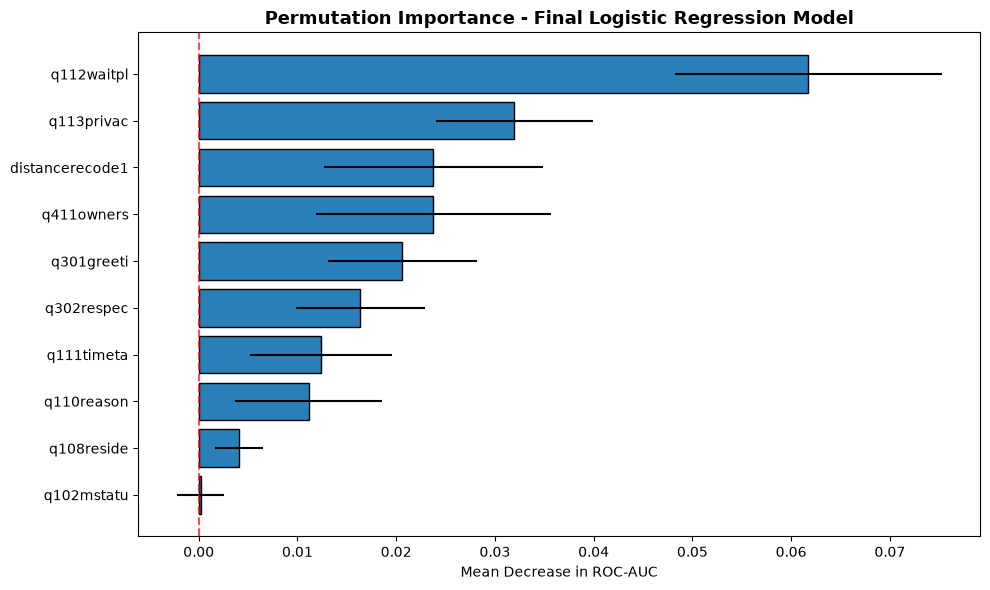

In [40]:
# Visualize
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2980b9' if v > 0 else '#e74c3c' for v in importance_final['Importance_Mean']]
ax.barh(importance_final['Feature'][::-1],
        importance_final['Importance_Mean'][::-1],
        xerr=importance_final['Importance_Std'][::-1],
        color=colors[::-1], edgecolor='black')
ax.set_title('Permutation Importance - Final Logistic Regression Model',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in ROC-AUC')
ax.axvline(x=0, color='red', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [41]:
# Logistic Regression Odds Ratios from model coefficients
# Extract feature names after one-hot encoding
ohe = best_model.named_steps['preprocessor'].named_transformers_['cat']
feature_names_ohe = ohe.get_feature_names_out(categorical_red)
coef = best_model.named_steps['classifier'].coef_[0]

odds_ratio_df = pd.DataFrame({
    'Feature': feature_names_ohe,
    'Coefficient': coef,
    'Odds_Ratio': np.exp(coef)
}).sort_values('Odds_Ratio', ascending=False)

print('Odds Ratios (top 15):')
print(odds_ratio_df.head(15).to_string(index=False))
print()
print('Odds Ratios (bottom 15 - negative effect):')
print(odds_ratio_df.tail(15).to_string(index=False))


Odds Ratios (top 15):
            Feature  Coefficient  Odds_Ratio
distancerecode1_2.0         0.73        2.07
     q102mstatu_3.0         0.25        1.28
     q102mstatu_2.0         0.07        1.07
     q102mstatu_5.0         0.03        1.03
     q102mstatu_4.0        -0.12        0.89
     q108reside_2.0        -0.26        0.77
     q110reason_2.0        -0.45        0.64
     q111timeta_2.0        -0.61        0.54
     q302respec_2.0        -0.73        0.48
     q301greeti_2.0        -0.80        0.45
     q411owners_2.0        -0.81        0.44
     q113privac_2.0        -1.02        0.36
     q112waitpl_2.0        -1.03        0.36

Odds Ratios (bottom 15 - negative effect):
            Feature  Coefficient  Odds_Ratio
distancerecode1_2.0         0.73        2.07
     q102mstatu_3.0         0.25        1.28
     q102mstatu_2.0         0.07        1.07
     q102mstatu_5.0         0.03        1.03
     q102mstatu_4.0        -0.12        0.89
     q108reside_2.0        -0.26  

---
## Step 12: Model Deployment
### 12.1 Save the Model

In [42]:
import os

model_path = 'Maternal_Satisfaction_LR_Final_Model.pkl'
joblib.dump(best_model, model_path)
print(f'Model saved to: {model_path}')
print(f'File size: {os.path.getsize(model_path)} bytes')


Model saved to: Maternal_Satisfaction_LR_Final_Model.pkl
File size: 3857 bytes


### 12.2 Load and Verify the Saved Model

In [43]:
loaded_model = joblib.load('Maternal_Satisfaction_LR_Final_Model.pkl')

# Verify predictions match
y_pred_loaded = loaded_model.predict(X_test_red)
print('Predictions match after loading:', np.array_equal(y_pred, y_pred_loaded))
print('Loaded model accuracy:', accuracy_score(y_test, y_pred_loaded))


Predictions match after loading: True
Loaded model accuracy: 0.8491620111731844


### 12.3 Prediction Function for New Observations

In [44]:
def predict_satisfaction(model, feature_names, new_obs_dict):
    '''
    Predict satisfaction for a new patient observation.

    Parameters:
    -----------
    model        : trained sklearn Pipeline
    feature_names: list of feature names (must match training features)
    new_obs_dict : dict mapping feature name -> coded value (matching SPSS codes)

    Returns:
    --------
    dict with predicted class and probability
    '''
    new_df = pd.DataFrame([new_obs_dict], columns=feature_names)
    pred_class = model.predict(new_df)[0]
    pred_prob  = model.predict_proba(new_df)[0]
    label_map = {0: 'Not Satisfied', 1: 'Satisfied'}
    return {
        'prediction': label_map[pred_class],
        'probability_not_satisfied': round(pred_prob[0], 4),
        'probability_satisfied': round(pred_prob[1], 4)
    }

# Example: predict for a hypothetical new patient
example_obs = {f: 1.0 for f in top10_features}  # all coded as category 1
result = predict_satisfaction(loaded_model, top10_features, example_obs)
print('Example prediction for new observation:')
for k, v in result.items():
    print(f'  {k}: {v}')


Example prediction for new observation:
  prediction: Satisfied
  probability_not_satisfied: 0.1518
  probability_satisfied: 0.8482


---
## Step 13: Summary & Conclusions

### Key Findings

| Metric | Value |
|--------|-------|
| Dataset | 894 mothers, Bahir Dar City Health Facilities |
| Outcome | Binary: Satisfied (2→1) vs Not Satisfied (1→0) |
| Algorithm | Logistic Regression |
| Feature Selection | Permutation Importance (top 10 from ~37 candidates) |
| Train/Test Split | 80% / 20% (stratified) |
| Cross-Validation | 5-fold Stratified |

### Interpretation Guidelines

- **Accuracy**: Overall proportion of correct predictions
- **Precision**: Of predicted satisfied, how many were truly satisfied
- **Recall**: Of truly satisfied mothers, how many were correctly identified
- **F1 Score**: Harmonic mean of precision and recall
- **ROC-AUC**: Ability to discriminate between satisfied and not-satisfied (higher = better)
- **Brier Score**: Calibration of probability predictions (lower = better)
- **Odds Ratio > 1**: Factor increases odds of satisfaction
- **Odds Ratio < 1**: Factor decreases odds of satisfaction


In [45]:
print('Maternal Satisfaction ML Project - Summary')
print('=' * 55)
print(f'Total observations  : {len(data)}')
print(f'Satisfied (%)       : {(y == 1).mean()*100:.1f}%')
print(f'Not Satisfied (%)   : {(y == 0).mean()*100:.1f}%')
print(f'Candidate features  : {len(candidate_features)}')
print(f'Selected features   : {len(top10_features)}')
print(f'Algorithm           : Logistic Regression')
print(f'Best C parameter    : {grid_search.best_params_["classifier__C"]}')
print()
print('Final Model Performance:')
print(f'  Accuracy  = {accuracy:.4f}')
print(f'  Precision = {precision:.4f}')
print(f'  Recall    = {recall:.4f}')
print(f'  F1-Score  = {f1:.4f}')
print(f'  ROC-AUC   = {roc_auc:.4f}')
print(f'  Brier     = {brier:.4f}')
print('=' * 55)


Maternal Satisfaction ML Project - Summary
Total observations  : 894
Satisfied (%)       : 61.4%
Not Satisfied (%)   : 38.6%
Candidate features  : 27
Selected features   : 10
Algorithm           : Logistic Regression
Best C parameter    : 0.1

Final Model Performance:
  Accuracy  = 0.8492
  Precision = 0.8673
  Recall    = 0.8909
  F1-Score  = 0.8789
  ROC-AUC   = 0.9190
  Brier     = 0.1209
